In [1]:
import numpy as np
import umap
import pickle

# Loading artifacts

In [2]:
import pickle

X_embed = np.load("../data/processed/embeddings.npy")
with open("../data/processed/kmeans_model.pkl", "rb") as f:
    km = pickle.load(f)

print(f"Loaded {X_embed.shape[0]} embeddings of dimension {X_embed.shape[1]}")

Loaded 26872 embeddings of dimension 384


# Fitting UMAP reducer

In [3]:
umap_reducer = umap.UMAP(
    n_components=2,
    metric='cosine',
    min_dist=0.1,
    n_neighbors=15,
    random_state=42
)

print("Running UMAP dimensionality reduction (this takes a few seconds)...")
X_umap = umap_reducer.fit_transform(X_embed)
print(f"UMAP Projection Shape: {X_umap.shape}")

Running UMAP dimensionality reduction (this takes a few seconds)...


/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


UMAP Projection Shape: (26872, 2)


# Visualising using UMAP reduction

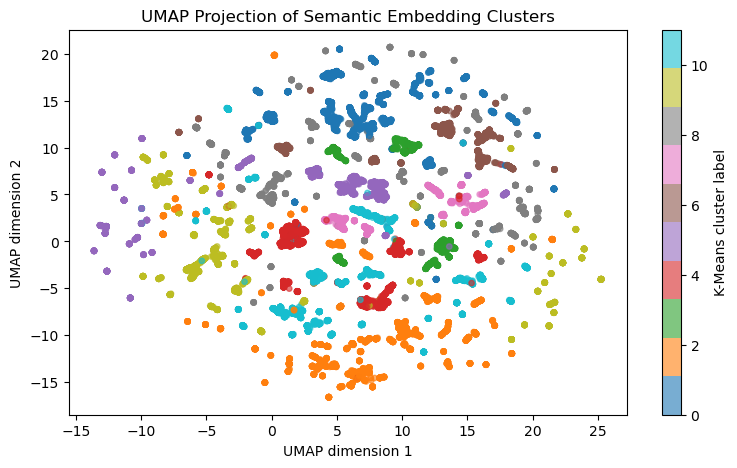

In [4]:
from matplotlib import pyplot as plt

plt.figure(figsize=(9,5))
scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=km.fit_predict(X_embed),
    cmap='tab10',
    alpha=0.6,
    s=15
)

plt.title("UMAP Projection of Semantic Embedding Clusters")
plt.xlabel('UMAP dimension 1')
plt.ylabel('UMAP dimension 2')
plt.colorbar(scatter, label="K-Means cluster label")
plt.show()